Dataset shape: (1036, 25)

First 5 records:
   laureateId         knownName  gender   birthDate birthCountry  \
0        1065    Henri B. Kagan    male  1930-12-15       France   
1        1066        Kenso Soai    male  1950-00-00        Japan   
2        1070  Michael Woodford    male  1955-00-00          USA   
3        1069    Robert E. Hall    male  1943-00-00          USA   
4        1067       Anne Carson  female  1950-06-21       Canada   

  birthContinent  awardYear           category portion  prizeAmount  ...  \
0         Europe       2026          Chemistry     1/2     12000000  ...   
1           Asia       2026          Chemistry     1/2     12000000  ...   
2  North America       2026  Economic Sciences     1/2     12000000  ...   
3  North America       2026  Economic Sciences     1/2     12000000  ...   
4  North America       2026         Literature       1     12000000  ...   

   isOrganization ageAtAward  \
0           False         96   
1           False         

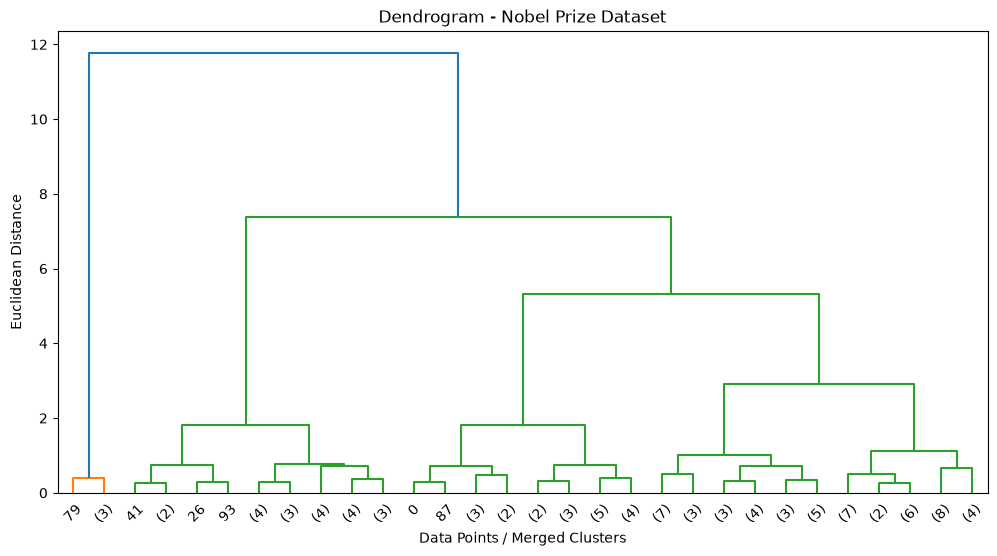

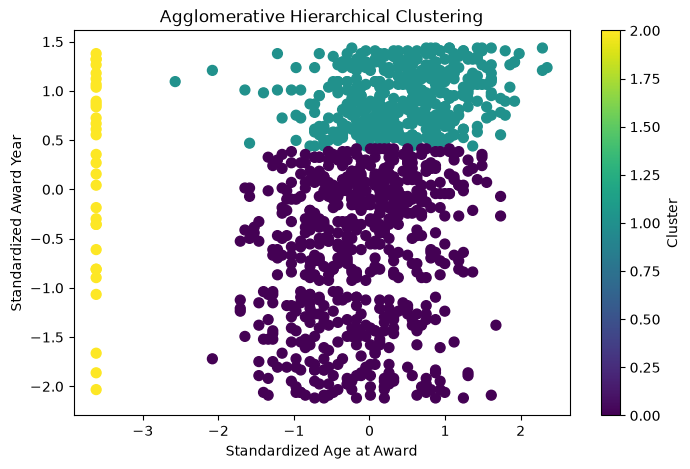


Cluster assignments:
[1 1 1 ... 0 0 0]

First 10 data points and their clusters:
Data Point: 0 Cluster: 1
Data Point: 1 Cluster: 1
Data Point: 2 Cluster: 1
Data Point: 3 Cluster: 1
Data Point: 4 Cluster: 1
Data Point: 5 Cluster: 1
Data Point: 6 Cluster: 1
Data Point: 7 Cluster: 1
Data Point: 8 Cluster: 1
Data Point: 9 Cluster: 1

Cluster Statistics:
                      ageAtAward    awardYear  prizeAmountAdjusted
Hierarchical_Cluster                                              
0                      56.932998  1952.319933         5.056515e+06
1                      66.002451  2009.012255         1.248089e+07
2                       0.000000  1980.870968         8.430136e+06

Hierarchical clustering completed successfully!
Output saved as nobel_prize_hierarchical_clustered.csv


In [1]:

# HIERARCHICAL CLUSTERING ON NOBEL PRIZE DATASET

# Step 1: Import required libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram, linkage

# Step 2: Load the dataset
df = pd.read_csv("nobel_prize_clustered.csv")

print("Dataset shape:", df.shape)
print("\nFirst 5 records:")
print(df.head())

# Step 3: Select numerical features
X = df[
    ["ageAtAward", "awardYear", "prizeAmountAdjusted"]
].copy()

# Convert columns to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Handle missing values
X = X.dropna()

print("\nSelected data shape:", X.shape)

# Step 4: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 5: Create a dendrogram
# Use a sample for better visualization
sample_size = min(100, len(X_scaled))

linked = linkage(
    X_scaled[:sample_size],
    method='ward'
)

plt.figure(figsize=(12, 6))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30
)

plt.title("Dendrogram - Nobel Prize Dataset")
plt.xlabel("Data Points / Merged Clusters")
plt.ylabel("Euclidean Distance")

plt.show()

# Step 6: Apply Agglomerative Clustering
model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

clusters = model.fit_predict(X_scaled)

# Step 7: Add cluster assignments
df_result = df.loc[X.index].copy()
df_result["Hierarchical_Cluster"] = clusters

# Step 8: Visualize the clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=50
)

plt.xlabel("Standardized Age at Award")
plt.ylabel("Standardized Award Year")

plt.title("Agglomerative Hierarchical Clustering")
plt.colorbar(label="Cluster")

plt.show()

# Step 9: Display cluster assignments
print("\nCluster assignments:")
print(clusters)

print("\nFirst 10 data points and their clusters:")

for i in range(min(10, len(clusters))):
    print(
        "Data Point:", i,
        "Cluster:", clusters[i]
    )

# Step 10: Display cluster statistics
print("\nCluster Statistics:")

print(
    df_result.groupby("Hierarchical_Cluster")[
        ["ageAtAward", "awardYear", "prizeAmountAdjusted"]
    ].mean()
)

# Step 11: Save the clustered dataset
df_result.to_csv(
    "nobel_prize_hierarchical_clustered.csv",
    index=False
)

print("\nHierarchical clustering completed successfully!")
print("Output saved as nobel_prize_hierarchical_clustered.csv")
